In [249]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit.Chem import Descriptors, Lipinski, MACCSkeys, AllChem

In [250]:
from sklearn.metrics import make_scorer
from sklearn.metrics import root_mean_squared_error
from scipy.stats import pearsonr

def rmse_norm(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)/(y_true.max() - y_true.min())

def pearson_corr(y_true, y_pred):
    corr = np.corrcoef(y_true, y_pred)[0, 1]
    return np.clip(corr, 0, 1)

def final_score(y_true, y_pred):
    nrmse = min(rmse_norm(y_true, y_pred), 1)
    pearson = pearson_corr(y_true, y_pred)
    return 0.5 * (1 - nrmse) + 0.5 * pearson

model_metric = make_scorer(final_score)


In [251]:
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")
df_train.drop(columns='ID', inplace=True)
print(f'train:{df_train.shape[0]}, test:{df_test.shape[0]}')
df_train.head()

train:1681, test:100


,Canonical_Smiles,Inhibition
0,Cl.OC1(Cc2cccc(Br)c2)CCNCC1,12.50
1,Brc1ccc2OCCc3ccnc1c23,4.45
2,CC1(CO)CC(=NO1)c2cc(c(F)cc2Cl)[N+](=O)[O-],4.92
3,Fc1ccc2nc(Nc3cccc(COc4cccc(c4)C(=O)N5CCOCC5)c3...,71.50
4,CC(C)CC(=O)C1=C(Nc2c(Cl)ccc(Cl)c2C1=O)S(=O)C,18.30


In [282]:
df_extra = pd.read_csv('DOWNLOAD-iUfY1SZQ1-3nL4RG25437oadYQOYesKnjiLvKOiSAc0_eq_.csv', sep=';')
df_extra_reduced = pd.DataFrame(df_extra[['Smiles','Value', 'Assay Description']])
df_extra_reduced.dropna(inplace=True)
extra_df_filtered = pd.DataFrame(df_extra_reduced[( df_extra_reduced['Assay Description'].str.contains('10 uM'))  & 
                                                  ( df_extra_reduced['Assay Description'].str.contains('CYP3A4')) &
                                                  (~df_extra_reduced['Assay Description'].str.contains('after'))  &
                                                  (~df_extra_reduced['Assay Description'].str.contains('min'))    & 
                                                  (~df_extra_reduced['Assay Description'].str.contains('time'))   &
                                                  (~df_extra_reduced['Assay Description'].str.contains('Time'))   &
                                                  (~df_extra_reduced['Assay Description'].str.contains('recombinant'))])

df_extra_final = pd.DataFrame(extra_df_filtered[['Smiles', 'Value']])
df_extra_final.reset_index(drop=True, inplace=True)
df_extra_final.columns = df_train.columns
df_extra_final['Inhibition'] = df_extra_final['Inhibition'] .clip(0,100)
print(f'extra:{df_extra_final.shape[0]}')
df_extra_final.head()

extra:864


,Canonical_Smiles,Inhibition
0,CN1CCN(Cc2ccc3c(ccn3S(=O)(=O)c3ccccc3)c2)CC1,5.47
1,C[C@@H](C(=O)Nc1nc(C(F)(F)F)co1)c1ccc(OS(=O)(=...,82.00
2,C[C@@H](C(=O)Nc1nncs1)c1ccc(OS(=O)(=O)C(F)(F)F...,66.00
3,CN(C)CC(=O)Nc1cc(CSc2ncccc2C(=O)Nc2ccc(OC(F)(F...,19.00
4,Cc1ccc(N(CCO)C(=O)Nc2ccc(-c3ncnc4[nH]cc(C)c34)...,5.00


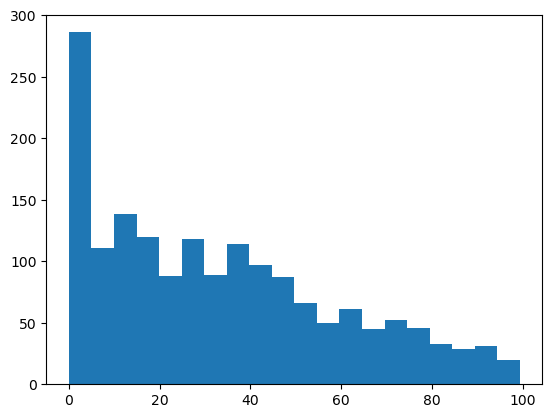

In [283]:
plt.hist(df_train['Inhibition'], bins=20)
plt.show()

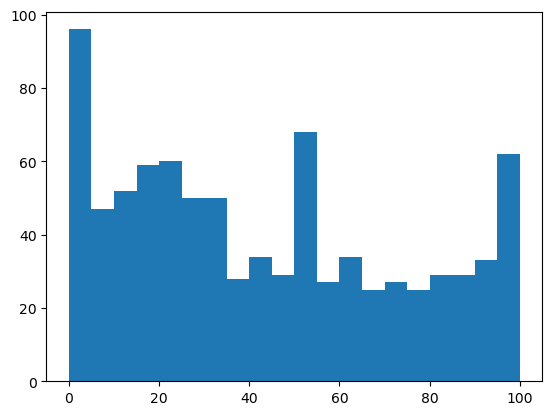

In [284]:
plt.hist(df_extra_final['Inhibition'], bins=20)
plt.show()

In [253]:
use_extra = True
if use_extra:
    df_final = pd.concat([df_train, df_extra_final])
    print(f'final:{df_final.shape[0]}')
else:
    df_final = pd.DataFrame(df_train)
    print(f'final:{df_final.shape[0]}')

final:2545


In [254]:
from rdkit.Chem import MolFromSmiles

df_final['mol'] = df_final['Canonical_Smiles'].apply(MolFromSmiles)
df_test['mol'] = df_test['Canonical_Smiles'].apply(MolFromSmiles)

In [255]:
from rdkit import Chem
from rdkit.Chem import AllChem

use_3d = False

def add_3d(mol):
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol

if use_3d:
    df_final['mol'] = df_final['mol'].apply(add_3d)
    df_test['mol'] = df_test['mol'].apply(add_3d)

In [256]:
from mordred import Calculator, descriptors

calc = Calculator(descriptors, ignore_3D= not use_3d)
mordred_columns = ['mordred_'+str(d) for d in calc.descriptors]

mordred_rows_train = []
mordred_rows_test = []

for mol in df_final['mol']:
    mordred = list(calc(mol))
    mordred_rows_train.append(mordred) 

for mol in df_test['mol']:
    mordred = list(calc(mol))
    mordred_rows_test.append(mordred) 

df_mordred_train = pd.DataFrame(mordred_rows_train, columns=mordred_columns)
df_mordred_test = pd.DataFrame(mordred_rows_test, columns=mordred_columns)


In [257]:
def convert_cell(cell):
    if isinstance(cell, (int, float)):
        return cell
    return np.nan

threshold = 0.1

df_mordred_train = df_mordred_train.map(convert_cell)
df_mordred_test = df_mordred_test.map(convert_cell)
null_ratio = df_mordred_train.isna().mean()
cols_to_drop = null_ratio[null_ratio > threshold].index
print(f"Dropping {len(cols_to_drop)} columns with > {threshold*100}% nulls.")
df_mordred_train.drop(columns=cols_to_drop, inplace=True)
df_mordred_test.drop(columns=cols_to_drop, inplace=True)

print(df_mordred_train.shape, df_mordred_test.shape)
df_mordred_train.head()


Dropping 170 columns with > 10.0% nulls.
(2545, 1443) (100, 1443)


,mordred_ABC,mordred_ABCGG,mordred_nAcid,mordred_nBase,mordred_SpAbs_A,mordred_SpMax_A,mordred_SpDiam_A,mordred_SpAD_A,mordred_SpMAD_A,mordred_LogEE_A,...,mordred_SRW10,mordred_TSRW10,mordred_MW,mordred_AMW,mordred_WPath,mordred_WPol,mordred_Zagreb1,mordred_Zagreb2,mordred_mZagreb1,mordred_mZagreb2
0,11.582017,9.872503,0,1,NaN,NaN,NaN,NaN,NaN,NaN,...,9.510667,47.985028,305.018204,9.242976,1500000372,19,76.0,85.0,NaN,3.291667
1,11.261338,9.066691,0,0,19.089482,2.475253,4.950505,19.089482,1.363534,3.613321,...,9.835369,46.651897,248.978926,11.317224,257,24,78.0,95.0,3.555556,3.027778
2,14.576853,13.260414,0,0,23.023055,2.455926,4.849638,23.023055,1.211740,3.869806,...,9.943237,66.589378,288.031313,9.932114,681,30,100.0,118.0,8.229167,4.152778
3,26.260410,18.280619,0,0,44.135195,2.413492,4.756906,44.135195,1.337430,4.437784,...,10.333808,83.075371,446.175419,7.967418,3823,49,176.0,205.0,8.361111,7.166667
4,16.815053,14.967307,0,0,26.340553,2.517453,5.034907,26.340553,1.197298,4.005703,...,10.164197,56.424768,359.014970,9.703107,948,39,114.0,136.0,10.111111,4.805556


In [258]:
r = 2
bit_size = 1024
morgan_columns = [f'morgan_{i}' for i in range(bit_size)]

morgan_rows_train = []
morgan_rows_test = []

for mol in df_final['mol']:
    morgan = AllChem.GetMorganFingerprintAsBitVect(mol, radius=r, nBits = bit_size)
    morgan_rows_train.append(np.array(morgan))

for mol in df_test['mol']:
    morgan = AllChem.GetMorganFingerprintAsBitVect(mol, radius=r, nBits = bit_size)
    morgan_rows_test.append(np.array(morgan))

df_morgan_train = pd.DataFrame(morgan_rows_train, columns=morgan_columns)
df_morgan_test = pd.DataFrame(morgan_rows_test, columns=morgan_columns)

print(df_morgan_train.shape, df_morgan_test.shape)
df_morgan_train.head()

(2545, 1024) (100, 1024)


,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,...,morgan_1014,morgan_1015,morgan_1016,morgan_1017,morgan_1018,morgan_1019,morgan_1020,morgan_1021,morgan_1022,morgan_1023
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [259]:
desc_columns = []
for desc_name, _ in Descriptors.descList:
    desc_columns.append('desc_' + desc_name)

desc_rows_train = []
desc_rows_test = []

for mol in df_final['mol']:
    desc = []
    for _, desc_func in Descriptors.descList:
        desc.append(desc_func(mol))

    desc_rows_train.append(desc)

for mol in df_test['mol']:
    desc = []
    for _, desc_func in Descriptors.descList:
        desc.append(desc_func(mol))

    desc_rows_test.append(desc)
    

df_desc_train = pd.DataFrame(np.array(desc_rows_train), columns=desc_columns)
df_desc_test = pd.DataFrame(np.array(desc_rows_test), columns=desc_columns)

In [260]:
def convert_cell(cell):
    if isinstance(cell, (int, float)):
        return cell
    return np.nan

threshold = 0.1

df_desc_train = df_desc_train.map(convert_cell)
df_desc_test = df_desc_test.map(convert_cell)
null_ratio = df_desc_train.isna().mean()
cols_to_drop = null_ratio[null_ratio > threshold].index
print(f"Dropping {len(cols_to_drop)} columns with > {threshold*100}% nulls.")
df_desc_train.drop(columns=cols_to_drop, inplace=True)
df_desc_test.drop(columns=cols_to_drop, inplace=True)

print(df_desc_train.shape, df_desc_test.shape)
df_desc_train.head()

Dropping 0 columns with > 10.0% nulls.
(2545, 217) (100, 217)


,desc_MaxAbsEStateIndex,desc_MaxEStateIndex,desc_MinAbsEStateIndex,desc_MinEStateIndex,desc_qed,desc_SPS,desc_MolWt,desc_HeavyAtomMolWt,desc_ExactMolWt,desc_NumValenceElectrons,...,desc_fr_sulfide,desc_fr_sulfonamd,desc_fr_sulfone,desc_fr_term_acetylene,desc_fr_tetrazole,desc_fr_thiazole,desc_fr_thiocyan,desc_fr_thiophene,desc_fr_unbrch_alkane,desc_fr_urea
0,10.360274,10.360274,0.000000,-0.507894,0.879876,18.875000,306.631,289.495,305.018204,90.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,5.589676,5.589676,0.771573,0.771573,0.716687,14.071429,250.095,242.031,248.978926,70.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,13.349148,13.349148,0.007074,-1.010940,0.682701,22.000000,288.662,278.582,288.031313,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,13.406186,13.406186,0.013275,-0.312444,0.456076,13.787879,446.482,423.298,446.175419,168.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,12.731366,12.731366,0.079233,-1.535218,0.843664,12.818182,360.262,345.142,359.014970,118.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [261]:
import inspect

def get_lipinski_functions():
    functions = {}
    for name, func in inspect.getmembers(Lipinski, inspect.isfunction):
        functions[name] = func
    return functions


def compute_props(mol):
    props = {}
    for name, func in all_funcs.items():
        try:
            props[name] = func(mol) if mol is not None else None
        except:
            props[name] = None
    return props

lipinski_funcs = get_lipinski_functions()
all_funcs = { **lipinski_funcs}

def convert_cell(cell):
    if isinstance(cell, (int, float)):
        return cell
    return np.nan

df_lipsinki_train = pd.DataFrame(df_final['mol'].apply(compute_props).to_list())
df_lipsinki_test = pd.DataFrame(df_test['mol'].apply(compute_props).to_list())

lipinski_column = [f'lipsinki_'+x for x in df_lipsinki_train.columns]
df_lipsinki_train.columns = lipinski_column
df_lipsinki_test.columns = lipinski_column

In [262]:
def convert_cell(cell):
    if isinstance(cell, (int, float)):
        return cell
    return np.nan

threshold = 0.1

df_lipsinki_train = df_lipsinki_train.map(convert_cell)
df_lipsinki_test = df_lipsinki_test.map(convert_cell)
null_ratio = df_lipsinki_train.isna().mean()
cols_to_drop = null_ratio[null_ratio > threshold].index
print(f"Dropping {len(cols_to_drop)} columns with > {threshold*100}% nulls.")
df_lipsinki_train.drop(columns=cols_to_drop, inplace=True)
df_lipsinki_test.drop(columns=cols_to_drop, inplace=True)

print(df_lipsinki_train.shape, df_lipsinki_test.shape)
df_lipsinki_train.head()

Dropping 4 columns with > 10.0% nulls.
(2545, 26) (100, 26)


,lipsinki_FractionCSP3,lipsinki_HeavyAtomCount,lipsinki_NHOHCount,lipsinki_NOCount,lipsinki_NumAliphaticCarbocycles,lipsinki_NumAliphaticHeterocycles,lipsinki_NumAliphaticRings,lipsinki_NumAmideBonds,lipsinki_NumAromaticCarbocycles,lipsinki_NumAromaticHeterocycles,...,lipsinki_NumHeterocycles,lipsinki_NumRotatableBonds,lipsinki_NumSaturatedCarbocycles,lipsinki_NumSaturatedHeterocycles,lipsinki_NumSaturatedRings,lipsinki_NumSpiroAtoms,lipsinki_NumUnspecifiedAtomStereoCenters,lipsinki_Phi,lipsinki_RingCount,lipsinki__fn
0,0.500000,16,2,2,0,1,1,0,1,0,...,1,2,0,1,1,0,0,5.248223,2,5.248223
1,0.181818,14,0,2,0,1,1,0,1,1,...,2,0,0,0,0,0,0,1.737573,3,1.737573
2,0.363636,19,1,6,0,1,1,0,1,0,...,1,3,0,0,0,0,1,3.421770,2,3.421770
3,0.200000,33,2,7,0,1,1,1,3,1,...,2,6,0,1,1,0,0,5.905438,5,5.905438
4,0.333333,22,1,4,0,0,0,0,1,1,...,1,4,0,0,0,0,1,5.096666,2,5.096666


In [263]:
maccs_columns = [f'maccs_{i}' for i in range(167)]

maccs_rows_train = []
maccs_rows_test = []

for mol in df_final['mol']:
    maccs = []
    maccs_rows_train.append(np.array(MACCSkeys.GenMACCSKeys(mol)))
    
for mol in df_test['mol']:
    maccs = []
    maccs_rows_test.append(np.array(MACCSkeys.GenMACCSKeys(mol)))


df_maccs_train = pd.DataFrame(np.array(maccs_rows_train), columns=maccs_columns)
df_maccs_test = pd.DataFrame(np.array(maccs_rows_test), columns=maccs_columns)

print(df_maccs_train.shape, df_maccs_test.shape)
df_maccs_train.head()

(2545, 167) (100, 167)


,maccs_0,maccs_1,maccs_2,maccs_3,maccs_4,maccs_5,maccs_6,maccs_7,maccs_8,maccs_9,...,maccs_157,maccs_158,maccs_159,maccs_160,maccs_161,maccs_162,maccs_163,maccs_164,maccs_165,maccs_166
0,0,0,0,0,0,0,0,0,0,0,...,1,1,0,0,1,1,1,1,1,1
1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,1,1,1,1,1,0
2,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,0
3,0,0,0,0,0,0,0,0,0,0,...,1,1,1,0,1,1,1,1,1,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,1,1,1,1,1,1,1,0


In [264]:
from sklearn.metrics.pairwise import pairwise_kernels
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import KernelPCA


def compute_gram_matrix(smiles_list1, smiles_list2, sigma=1, reg=1e-10, num_iters=1000):
    X1 = smiles_list1[:]
    X2 = smiles_list2[:]
    
    # Check for empty or NoneType molecules
    X1 = [x for x in X1 if x is not None]
    X2 = [x for x in X2 if x is not None]
    
    if len(X1) == 0 or len(X2) == 0:
        return None

    r = 2
    bit_size = 2048
    
    X1_feats = np.array([AllChem.GetMorganFingerprintAsBitVect(mol, radius=r, nBits = bit_size)for mol in X1])
    X2_feats = np.array([AllChem.GetMorganFingerprintAsBitVect(mol, radius=r, nBits = bit_size) for mol in X2])

    
    dist_matrix = pairwise_kernels(X1_feats, X2_feats)


    # use Sinkhorn-Knopp algorithm to compute kernel matrix
    n = dist_matrix.shape[0]
    m = dist_matrix.shape[1]
    a = np.ones(n) / n
    b = np.ones(m) / m
    K = np.exp(-dist_matrix / sigma)
    # K = dist_matrix / sigma
    K /= K.sum()

    for i in range(num_iters):
        u = reg * np.log(a)
        v = reg * np.log(b + 1e-08)
        M = (-sigma * K + u.reshape(-1, 1) + v.reshape(1, -1)) / reg
        row_ind, col_ind = linear_sum_assignment(M)
        pi = np.zeros((n, m))
        pi[row_ind, col_ind] = 1
        a_new = pi.sum(axis=1)
        b_new = pi.sum(axis=0)
        if np.abs(a_new - a).max() < 1e-6 and np.abs(b_new - b).max() < 1e-6:
            break
        a = a_new
        b = b_new

    K = np.diag(a).dot(K).dot(np.diag(b))
    return K

In [265]:
mols_concat = pd.concat([df_final['mol'],  df_test['mol']])
kernel = compute_gram_matrix(mols_concat, mols_concat)
n_components = 300
kpca_columns  = [f'kpca_{i}' for i in range(n_components)]

kpca = KernelPCA(n_components=n_components, kernel='precomputed')
df_kpca = pd.DataFrame(kpca.fit_transform(kernel), columns= kpca_columns)

df_kpca_train = pd.DataFrame(df_kpca.iloc[:df_final.shape[0]])
df_kpca_test = pd.DataFrame(df_kpca.iloc[df_final.shape[0]:])
df_kpca_test.reset_index(drop=True, inplace=True)

print(df_kpca_train.shape, df_kpca_test.shape)
df_kpca_train.head()

(2545, 300) (100, 300)


,kpca_0,kpca_1,kpca_2,kpca_3,kpca_4,kpca_5,kpca_6,kpca_7,kpca_8,kpca_9,...,kpca_290,kpca_291,kpca_292,kpca_293,kpca_294,kpca_295,kpca_296,kpca_297,kpca_298,kpca_299
0,0.000102,-0.000156,0.000337,-0.000153,0.000196,-0.000238,3.927203e-06,-0.000057,0.000405,0.000125,...,0.000110,1.169298e-04,0.000005,-0.000094,0.000024,-0.000179,-0.000058,2.089554e-07,3.358495e-06,-0.000112
1,0.001171,-0.001435,0.000074,0.000301,0.001022,-0.000644,-6.369257e-04,0.000137,-0.000371,0.000255,...,0.000010,4.434797e-05,-0.000024,0.000022,0.000009,-0.000044,0.000030,-2.835913e-05,-5.696783e-05,0.000019
2,-0.000276,-0.000107,-0.000113,-0.000060,0.000007,0.000107,1.393129e-04,0.000002,0.000052,0.000030,...,-0.000013,-6.876975e-05,0.000030,-0.000010,0.000006,-0.000022,-0.000019,-6.177467e-05,-7.959995e-07,0.000060
3,-0.000401,-0.000103,-0.000068,-0.000018,-0.000091,0.000070,4.892349e-07,0.000074,-0.000032,0.000019,...,-0.000002,-2.025621e-07,-0.000003,-0.000014,0.000002,-0.000003,-0.000003,8.284093e-06,3.285989e-06,0.000008
4,-0.000093,0.000174,0.000108,-0.000022,0.000337,-0.000155,1.952058e-04,0.000045,-0.000004,0.000072,...,0.000024,2.521222e-05,0.000084,-0.000007,-0.000043,0.000007,-0.000042,1.368392e-05,9.205830e-05,0.000016


In [266]:

from smiles_transformer.pretrain_trfm import TrfmSeq2seq
from smiles_transformer.build_vocab import WordVocab
from smiles_transformer.utils import split
import torch

vocab = WordVocab.load_vocab('pretrained/vocab.pkl')
trfm = TrfmSeq2seq(len(vocab), 256, len(vocab), 3)
trfm.load_state_dict(torch.load('pretrained/pretrained_trfm.pkl'), strict=False)


pad_index = 0
unk_index = 1
eos_index = 2
sos_index = 3
mask_index = 4

def get_inputs(sm):
    seq_len = 220
    sm = sm.split()
    if len(sm)>218:
        print('SMILES is too long ({:d})'.format(len(sm)))
        sm = sm[:109]+sm[-109:]
    ids = [vocab.stoi.get(token, unk_index) for token in sm]
    ids = [sos_index] + ids + [eos_index]
    seg = [1]*len(ids)
    padding = [pad_index]*(seq_len - len(ids))
    ids.extend(padding), seg.extend(padding)
    return ids, seg

def get_array(smiles):
    x_id, x_seg = [], []
    for sm in smiles:
        a,b = get_inputs(sm)
        x_id.append(a)
        x_seg.append(b)
    return torch.tensor(x_id), torch.tensor(x_seg)

c:\Users\eujim\anaconda3\envs\bmbmbm\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


In [267]:
from mol2vec.features import mol2alt_sentence, mol2sentence, MolSentence, DfVec, sentences2vec
from gensim.models import word2vec

model = word2vec.Word2Vec.load('pretrained/model_300dim.pkl')
sentence_train = df_final.apply(lambda x: MolSentence(mol2alt_sentence(x['mol'], 1)), axis=1)
mol2vec_train = [DfVec(x) for x in sentences2vec(sentence_train, model, unseen='UNK')]
df_m2v_train = pd.DataFrame([x.vec for x in mol2vec_train])

sentence_test = df_test.apply(lambda x: MolSentence(mol2alt_sentence(x['mol'], 1)), axis=1)
mol2vec_test = [DfVec(x) for x in sentences2vec(sentence_test, model, unseen='UNK')]
df_m2v_test = pd.DataFrame([x.vec for x in mol2vec_test])

m2v_columns = [f'm2v_{i}' for i in range(df_m2v_train.shape[1])]
df_m2v_train.columns = m2v_columns
df_m2v_test.columns = m2v_columns

print(df_m2v_train.shape, df_m2v_test.shape)
df_m2v_train.head()

(2545, 300) (100, 300)


,m2v_0,m2v_1,m2v_2,m2v_3,m2v_4,m2v_5,m2v_6,m2v_7,m2v_8,m2v_9,...,m2v_290,m2v_291,m2v_292,m2v_293,m2v_294,m2v_295,m2v_296,m2v_297,m2v_298,m2v_299
0,1.334728,0.699145,-1.691746,3.931750,-1.321514,-1.498074,-5.951805,1.646858,2.490505,1.354962,...,-1.092954,8.691928,3.060855,0.016588,-6.665393,-3.614873,-3.358906,-3.396379,-4.614727,-0.306338
1,2.307962,-2.539482,-2.439354,4.005458,-1.128375,1.341786,-4.766161,0.573499,1.543363,1.632616,...,-1.740424,7.462520,3.776924,-1.140175,-5.390016,-2.429200,-5.444958,-3.068465,-4.386703,-0.058140
2,1.867832,0.222862,-1.771686,2.427125,-3.027487,0.060601,-8.155186,2.710227,2.888850,1.939111,...,-0.099660,7.306002,6.604412,-3.277866,-6.330505,-4.611368,-5.061002,-5.035862,-6.157926,0.630808
3,4.671403,-5.767117,-4.327458,10.862745,-1.891158,1.023415,-13.892540,-0.268305,9.414639,3.557178,...,-1.134155,14.314648,12.709277,-2.019380,-9.426249,-5.736713,-7.553767,-4.668036,-13.057094,-2.479265
4,-1.116712,-1.119151,-4.191337,2.055569,-0.256953,5.379906,-7.650583,-1.092347,7.626406,-1.984802,...,-0.758092,6.969676,10.895550,1.254545,-5.791404,-1.587832,-2.235075,-3.433151,-12.340335,-1.931021


In [268]:
smiles_split_train = [split(sm) for sm in df_final['Canonical_Smiles']]
smiles_split_test = [split(sm) for sm in df_test['Canonical_Smiles']]

xid_train, xseg_train = get_array(smiles_split_train)
xid_test, xseg_test = get_array(smiles_split_test)

smiles_encoded_train = trfm.encode(torch.t(xid_train))
smiles_encoded_test = trfm.encode(torch.t(xid_test))

st_columns = [f'st_{i}' for i in range(smiles_encoded_train.shape[1])]
df_st_train = pd.DataFrame(smiles_encoded_train, columns=st_columns)
df_st_test = pd.DataFrame(smiles_encoded_test, columns=st_columns)

print(df_st_train.shape, df_st_test.shape)
df_st_train.head()

There are 2545 molecules. It will take a little time.
(2545, 1024) (100, 1024)


,st_0,st_1,st_2,st_3,st_4,st_5,st_6,st_7,st_8,st_9,...,st_1014,st_1015,st_1016,st_1017,st_1018,st_1019,st_1020,st_1021,st_1022,st_1023
0,0.217822,0.840265,-0.171835,-0.104773,-0.297168,0.167093,-0.065471,0.252806,-0.322064,0.020391,...,-1.393897,0.388344,-0.125222,-0.110165,0.756492,0.517294,-0.894819,1.103833,1.699941,0.922741
1,0.069872,0.775950,-0.139049,-0.159851,-0.346707,-0.006188,0.000693,0.200485,-0.178273,-0.035963,...,-1.397074,1.274039,-0.895592,-0.242155,0.038253,0.641346,-0.499050,-0.115513,1.352567,0.973625
2,0.077916,0.290826,0.087006,-0.056246,-0.305229,-0.174068,-0.101186,-0.015507,-0.075255,-0.884513,...,-1.715724,0.194660,0.221713,-0.415048,0.884250,0.383754,-1.013425,0.560985,1.641201,1.056429
3,0.268177,0.425594,-0.096584,-0.165110,-0.261614,-0.094314,0.194023,0.066702,-0.259525,-0.280930,...,-2.020153,0.798497,-0.249966,-0.288279,0.913408,0.395608,-0.916150,0.569296,2.292328,0.314771
4,0.141958,0.546730,-0.141244,-0.062356,0.027300,0.244160,0.007351,0.364093,-0.218910,-0.346848,...,-1.867126,0.212301,0.776355,-0.041653,0.127814,0.400536,-1.032168,0.808463,2.160835,0.739324


In [285]:
y_train = np.array(pd.concat([df_train['Inhibition'], df_extra_final['Inhibition']]))
y_train.shape

(2545,)

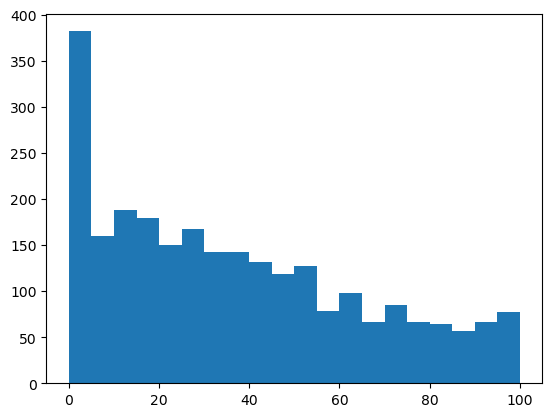

In [286]:
plt.hist(y_train, bins=20)
plt.show()

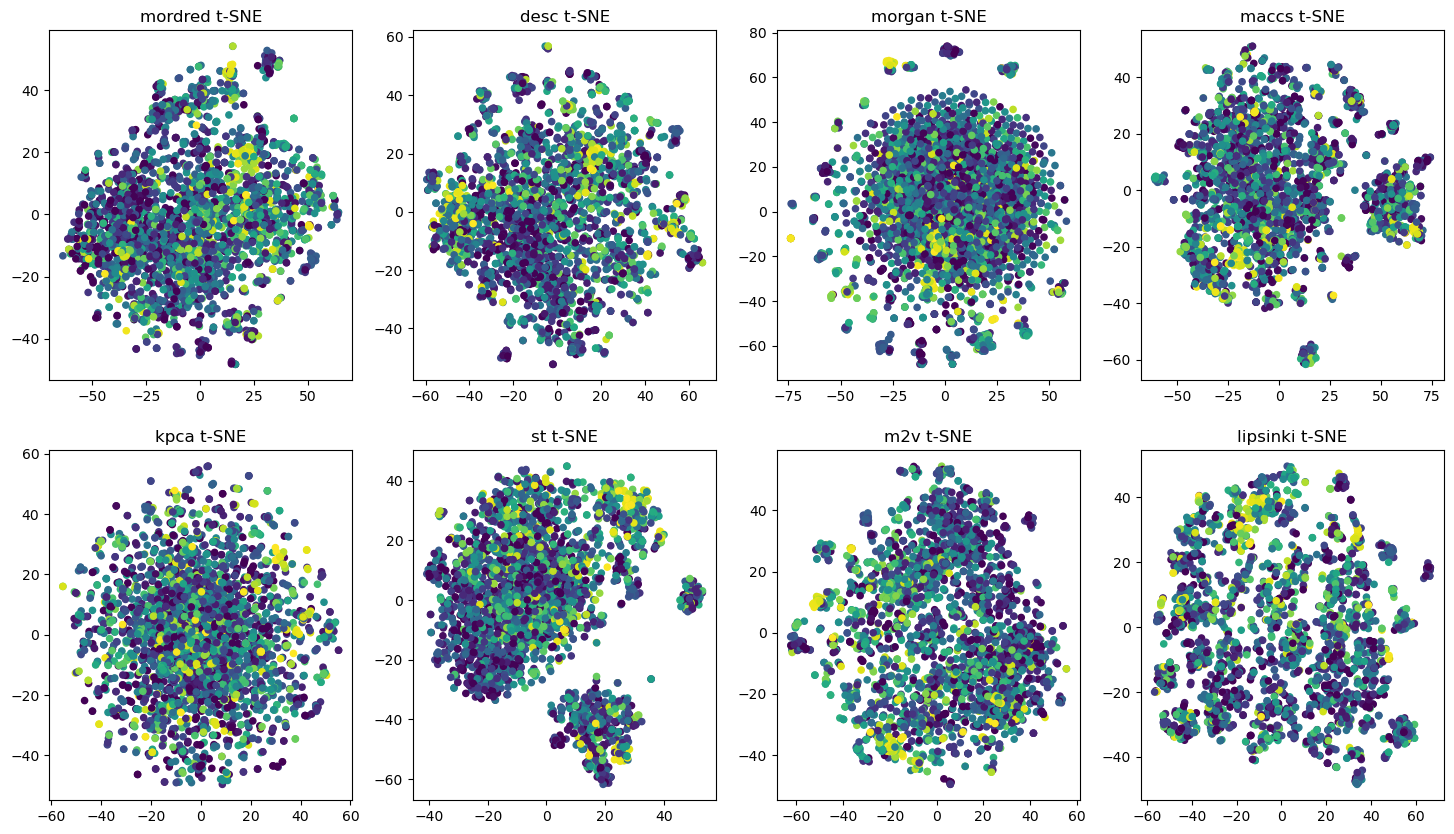

In [287]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
mordered_train_scaled = scaler.fit_transform(df_mordred_train.fillna(df_mordred_train.mean(numeric_only=True)))
desc_train_scaled = scaler.fit_transform(df_desc_train.fillna(df_desc_train.mean(numeric_only=True)))
morgan_train_scaled = scaler.fit_transform(df_morgan_train)
maccs_train_scaled = scaler.fit_transform(df_maccs_train)
kpca_train_scaled = scaler.fit_transform(df_kpca_train)
st_train_scaled = scaler.fit_transform(df_st_train)
m2v_train_scaled = scaler.fit_transform(df_m2v_train)
lipsinki_train_scaled = scaler.fit_transform(df_lipsinki_train)

tsne = TSNE(n_components=2, perplexity=30, max_iter=1000)
mordred_tsne = tsne.fit_transform(mordered_train_scaled)
desc_tsne = tsne.fit_transform(desc_train_scaled)
morgan_tsne = tsne.fit_transform(morgan_train_scaled)
maccs_tsne = tsne.fit_transform(maccs_train_scaled)
kpca_tsne = tsne.fit_transform(kpca_train_scaled)
st_tsne = tsne.fit_transform(st_train_scaled)
m2v_tsne = tsne.fit_transform(m2v_train_scaled)
lipsinki_tsne = tsne.fit_transform(lipsinki_train_scaled)

fig, axes = plt.subplots(2, 4, figsize=(18, 10))

axes[0,0].scatter(mordred_tsne[:, 0], mordred_tsne[:, 1], c=y_train, s=20)
axes[0,0].set_title('mordred t-SNE')

axes[0,1].scatter(desc_tsne[:, 0], desc_tsne[:, 1], c=y_train, s=20)
axes[0,1].set_title('desc t-SNE')

axes[0,2].scatter(morgan_tsne[:, 0], morgan_tsne[:, 1], c=y_train, s=20)
axes[0,2].set_title('morgan t-SNE')

axes[0,3].scatter(maccs_tsne[:, 0], maccs_tsne[:, 1], c=y_train, s=20)
axes[0,3].set_title('maccs t-SNE')

axes[1,0].scatter(kpca_tsne[:, 0], kpca_tsne[:, 1], c=y_train, s=20)
axes[1,0].set_title('kpca t-SNE')

axes[1,1].scatter(st_tsne[:, 0], st_tsne[:, 1], c=y_train, s=20)
axes[1,1].set_title('st t-SNE')

axes[1,2].scatter(m2v_tsne[:, 0], m2v_tsne[:, 1], c=y_train, s=20)
axes[1,2].set_title('m2v t-SNE')

axes[1,3].scatter(lipsinki_tsne[:, 0], lipsinki_tsne[:, 1], c=y_train, s=20)
axes[1,3].set_title('lipsinki t-SNE')

plt.show()


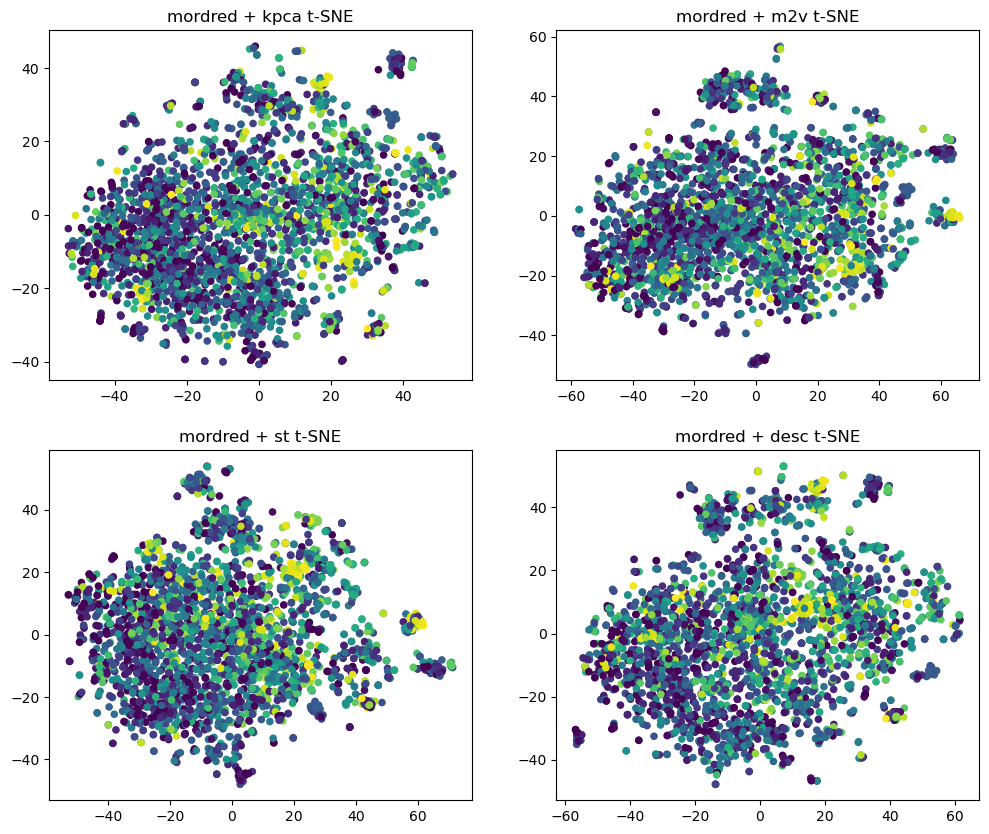

In [288]:
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000)
mordred_kpca_tsne = tsne.fit_transform(np.hstack([mordered_train_scaled, kpca_train_scaled]))
mordred_m2v_tsne = tsne.fit_transform(np.hstack([mordered_train_scaled, m2v_train_scaled]))
mordred_st_tsne = tsne.fit_transform(np.hstack([mordered_train_scaled, st_train_scaled]))
mordred_desc_tsne = tsne.fit_transform(np.hstack([mordered_train_scaled, desc_train_scaled]))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0,0].scatter(mordred_kpca_tsne[:, 0], mordred_kpca_tsne[:, 1], c=y_train, s=20)
axes[0,0].set_title('mordred + kpca t-SNE')

axes[0,1].scatter(mordred_m2v_tsne[:, 0], mordred_m2v_tsne[:, 1], c=y_train, s=20)
axes[0,1].set_title('mordred + m2v t-SNE')

axes[1,0].scatter(mordred_st_tsne[:, 0], mordred_st_tsne[:, 1], c=y_train, s=20)
axes[1,0].set_title('mordred + st t-SNE')


axes[1,1].scatter(mordred_desc_tsne[:, 0], mordred_desc_tsne[:, 1], c=y_train, s=20)
axes[1,1].set_title('mordred + desc t-SNE')
plt.show()

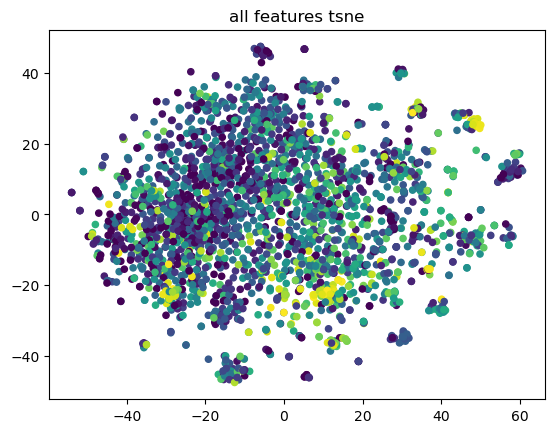

In [289]:
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000)
all_tsne = tsne.fit_transform(np.hstack([
    morgan_train_scaled, mordered_train_scaled, maccs_train_scaled, desc_train_scaled, kpca_train_scaled, st_train_scaled, m2v_train_scaled, lipsinki_train_scaled]))
plt.scatter(all_tsne[:,0], all_tsne[:,1], c=y_train, s=20)
plt.title('all features tsne')
plt.show()

In [290]:
df_features_train = pd.concat([df_mordred_train, df_desc_train, df_morgan_train,  df_lipsinki_train] , axis=1)
df_features_test = pd.concat([df_mordred_test,  df_desc_test, df_morgan_test,  df_lipsinki_test] , axis=1)
df_features_train.fillna(df_features_train.mean(numeric_only=True), inplace=True)
df_features_test.fillna(df_features_test.mean(numeric_only=True), inplace=True)

X_train = np.array(df_features_train)
X_test = np.array(df_features_test)

X_train.shape, X_test.shape

((2545, 2710), (100, 2710))

In [291]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [292]:
from sklearn.ensemble import RandomForestRegressor

pre_model = RandomForestRegressor(n_estimators=300)
pre_model.fit(X_train_scaled,y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


total features:2710
importance 0 features: 182
importance over 0.0012 features: 113


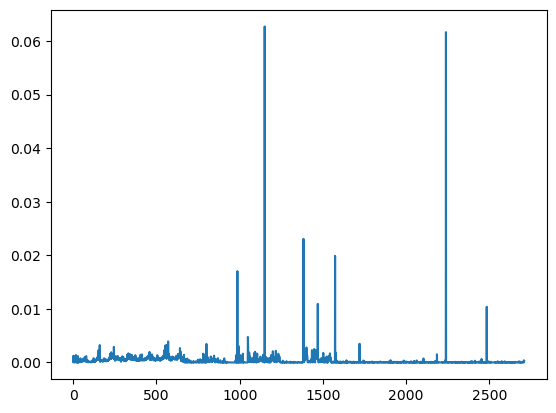

In [299]:
importance = pre_model.feature_importances_
features = df_features_train.columns
importance_threshold = 0.0012
filter_idx = np.sum(importance > importance_threshold)

plt.plot(range(importance.size), pre_model.feature_importances_)

print(f'total features:{importance.size}')
print(f'importance 0 features: {np.sum(importance == 0)}')
print(f'importance over {importance_threshold} features: {filter_idx}')

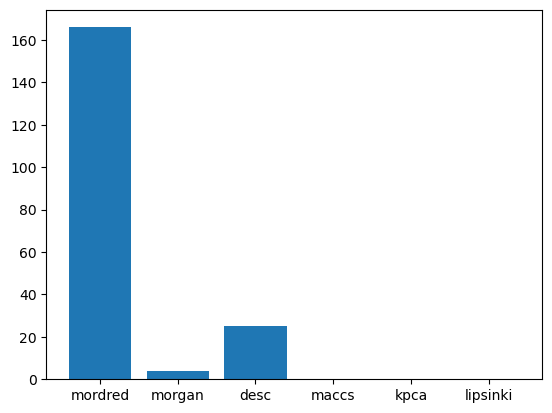

{'mordred': 0.85, 'morgan': 0.02, 'desc': 0.13, 'maccs': 0.0, 'kpca': 0.0, 'lipsinki': 0.0}
0 mordred_FilterItLogS
1 morgan_579
2 mordred_SLogP
3 desc_MolLogP
4 mordred_SaasC
5 desc_AvgIpc
6 morgan_824
7 mordred_MAXaaCH
8 mordred_GATS2s
9 mordred_MAXaasC
10 morgan_60
11 mordred_Xch-5dv
12 mordred_GATS3d
13 mordred_AATS7s
14 mordred_GATS2dv
15 mordred_SaaNH
16 mordred_ATSC2dv
17 mordred_JGI5
18 mordred_BCUTc-1h
19 desc_qed
20 desc_MaxAbsPartialCharge
21 desc_BCUT2D_MRLOW
22 mordred_TSRW10
23 mordred_AATS0s
24 desc_MinPartialCharge
25 mordred_GATS2c
26 mordred_AMID_O
27 mordred_VSA_EState4
28 mordred_BCUTd-1h
29 mordred_ETA_dEpsilon_C
30 mordred_MATS2dv
31 desc_fr_Al_COO
32 mordred_AATS4i
33 mordred_JGI6
34 mordred_GATS5c
35 mordred_MINaaCH
36 mordred_ETA_shape_y
37 desc_PEOE_VSA8
38 mordred_BCUTc-1l
39 mordred_ETA_epsilon_2
40 desc_VSA_EState4
41 mordred_ATSC8p
42 mordred_ETA_psi_1
43 mordred_JGI2
44 mordred_GATS1dv
45 mordred_AATS5s
46 mordred_RPCG
47 mordred_IC2
48 mordred_SssS
49 mor

In [295]:
prefixes = ["mordred", "morgan", "desc", 'maccs','kpca', 'lipsinki']
counts = {prefix: sum([s.startswith(prefix) for s in features[(np.argsort(importance)[::-1])[:filter_idx]]]) for prefix in prefixes}

plt.bar(counts.keys(), counts.values())
plt.show()

ratio = dict(zip(counts.keys(), map(lambda x: round(x/filter_idx,2) ,list(counts.values()))))
print(ratio)

for n, imp in enumerate(features[np.argsort(importance)[::-1]]):
    print(n, imp)

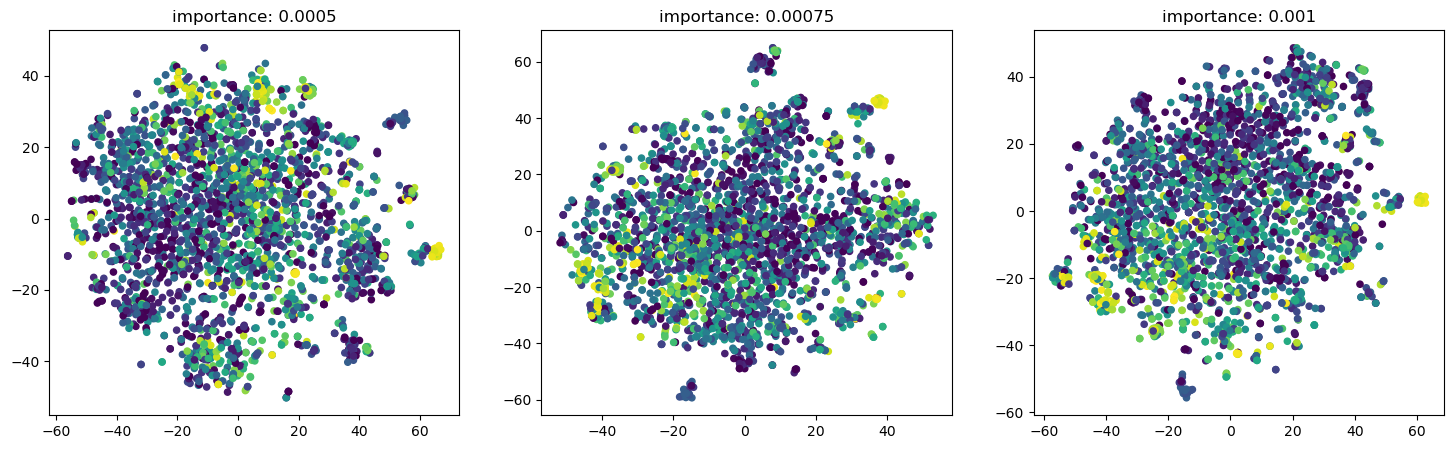

In [296]:
thresholds = [0.0005, 0.00075, 0.001]
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000)
tsnes = []

for th in thresholds:
    filtered_idx = importance < th
    filtered = np.delete(X_train_scaled, filtered_idx, axis=1)
    tsnes.append(tsne.fit_transform(filtered))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(tsnes[0][:, 0],tsnes[0][:, 1], c=y_train, s=20)
axes[0].set_title(f'importance: {thresholds[0]}')

axes[1].scatter(tsnes[1][:, 0], tsnes[1][:, 1], c=y_train, s=20)
axes[1].set_title(f'importance: {thresholds[1]}')

axes[2].scatter(tsnes[2][:, 0], tsnes[2][:, 1], c=y_train, s=20)
axes[2].set_title(f'importance: {thresholds[2]}')

plt.show()

In [300]:
filtered_idx = importance < importance_threshold
X_train_filtered = np.delete(X_train_scaled, filtered_idx, axis=1)
X_test_filtered = np.delete(X_test_scaled, filtered_idx, axis=1)

X_train_filtered.shape, X_test_filtered.shape

((2545, 113), (100, 113))

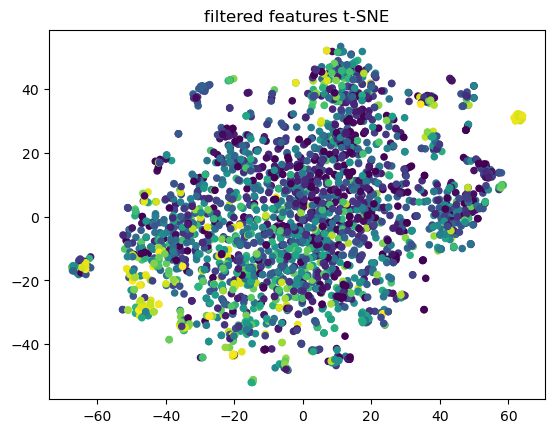

In [301]:
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000)
filtered_tsne = tsne.fit_transform(X_train_filtered)
plt.scatter(filtered_tsne[:,0], filtered_tsne[:,1], c=y_train, s=20)
plt.title('filtered features t-SNE')
plt.show()

In [302]:
import xgboost as xgb
import cupy as cp
from sklearn.model_selection import train_test_split, StratifiedKFold

xgb.set_config(verbosity=0)


model = xgb.XGBRegressor(
        n_estimators=5000,  max_depth = 5, learning_rate = 0.01,
        early_stopping_rounds= 200, 
        tree_method="hist",device="cuda"
    )

y_binned = pd.qcut(y_train, q=10, duplicates='drop')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


scores = []
for train_idx, val_idx in skf.split(X_train_filtered, y_binned.codes):
    X_tr, X_val = X_train_filtered[train_idx], X_train_filtered[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    model.fit(cp.array(X_tr), y_tr, eval_set=[(X_val, y_val)],  verbose=False)
    preds = model.predict(cp.array(X_val))
    rmse_score = rmse_norm(y_true=y_val, y_pred=preds)
    pearson_score = pearson_corr(y_true=y_val, y_pred=preds)
    score = final_score(y_val, preds)
    scores.append((rmse_score, pearson_score, score))


np.mean(scores, axis=0)


array([0.22971802, 0.58427234, 0.67727716])

In [324]:
y_binned = pd.qcut(y_train[:1500], q=10, duplicates='drop')
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
val_base_idx = np.arange(1500)

model = xgb.XGBRegressor(
        n_estimators=5000,  max_depth = 5, learning_rate = 0.01,
        early_stopping_rounds= 200, 
        tree_method="hist",device="cuda"
    )

scores = []
for _, val_sub_idx in skf.split(X_train_filtered[:1500], y_binned.codes):
    val_idx = val_base_idx[val_sub_idx]
    train_idx = np.setdiff1d(np.arange(y_train.size), val_idx)
    X_tr, X_val = X_train_filtered[train_idx], X_train_filtered[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    model.fit(cp.array(X_tr), y_tr, eval_set=[(X_val, y_val)],  verbose=False)
    preds = model.predict(cp.array(X_val))
    rmse_score = rmse_norm(y_true=y_val, y_pred=preds)
    pearson_score = pearson_corr(y_true=y_val, y_pred=preds)
    score = final_score(y_val, preds)
    scores.append((rmse_score, pearson_score, score))


np.mean(scores, axis=0)

array([0.24154423, 0.42794379, 0.59319978])

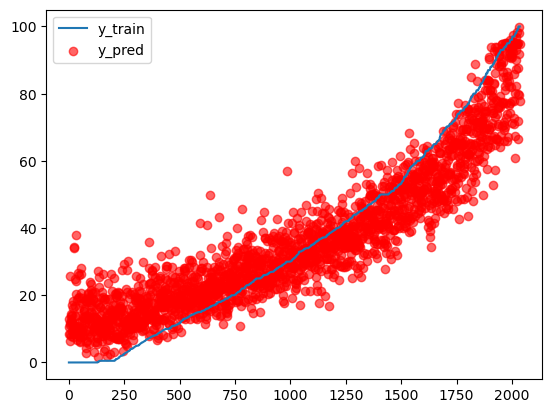

rmse:0.10899556118070546 pearson_corr:0.9442379052539175
score:0.9176211720366061


In [303]:
y_sorted_idx = np.argsort(y_tr)
y_train_pred = model.predict(X_tr)

plt.plot(np.arange(y_tr.size), np.sort(y_tr), label='y_train')
plt.scatter(np.arange(y_tr.size), y_train_pred[y_sorted_idx],c='r', alpha=0.6, label= 'y_pred')
plt.legend()
plt.show()

print(f'rmse:{rmse_norm(y_tr,y_train_pred)} pearson_corr:{pearson_corr(y_tr, y_train_pred)}')
print(f'score:{final_score(y_tr,y_train_pred)}')

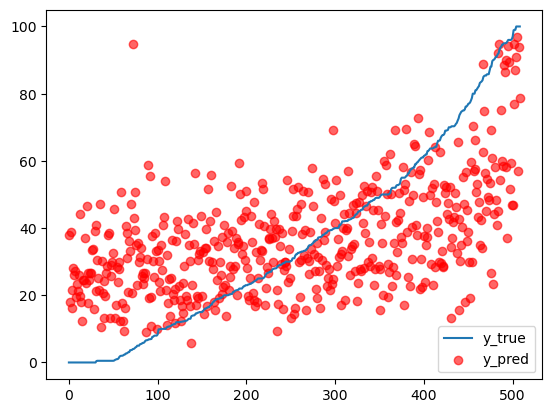

rmse:0.233026469522294 pearson_corr:0.5704989044912191
score:0.6687362174844625


In [304]:
y_sorted_idx = np.argsort(y_val)

plt.plot(np.arange(y_val.size), np.sort(y_val), label='y_true')
plt.scatter(np.arange(y_val.size), preds[y_sorted_idx],c='r', alpha=0.6, label= 'y_pred')
plt.legend()
plt.show()

print(f'rmse:{rmse_norm(y_val,preds)} pearson_corr:{pearson_corr(y_val, preds)}')
print(f'score:{final_score(y_val, preds)}')

In [245]:
import optuna
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from lightgbm import LGBMRegressor

def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 500, 3000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        "gamma": trial.suggest_float("gamma", 0, 3.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 3),
        'tree_method':'hist',
        'device':'cuda'
    }

    model = xgb.XGBRegressor(**params)

    y_binned = pd.qcut(y_train, q=10, duplicates='drop')
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # 수동 cross-validation loop → bin 정보를 split에 반영
    scores = []
    for train_idx, val_idx in skf.split(X_train_filtered, y_binned.codes):
        X_tr, X_val = X_train_filtered[train_idx], X_train_filtered[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        score = final_score(y_val, preds)
        scores.append(score)

    mean_score = np.mean(scores)
    return mean_score

def objective_lgb(trial):
    params = {
        'objective': 'regression',
        'boosting_type': 'gbdt',
        'device': 'gpu',
        'verbosity': -1,
        'num_leaves': trial.suggest_int('num_leaves', 20, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 3000),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
    }
    model = LGBMRegressor(**params)

    y_binned = pd.qcut(y_train, q=10, duplicates='drop')
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # 수동 cross-validation loop → bin 정보를 split에 반영
    scores = []
    for train_idx, val_idx in skf.split(X_train_filtered, y_binned.codes):
        X_tr, X_val = X_train_filtered[train_idx], X_train_filtered[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model.fit(np.array(X_tr), np.array(y_tr), feature_name=None)
        preds = model.predict(np.array(X_val))
        score = final_score(y_val, preds)
        scores.append(score)

    mean_score = np.mean(scores)
    return mean_score

# 실행
study = optuna.create_study(direction='maximize')
study.optimize(objective_xgb, n_trials=200)

[I 2025-07-15 14:19:33,283] A new study created in memory with name: no-name-954d2144-f055-4b89-a7b2-2201e7713984
[I 2025-07-15 14:19:48,485] Trial 0 finished with value: 0.6131057258377111 and parameters: {'n_estimators': 1919, 'max_depth': 4, 'learning_rate': 0.05083055928812499, 'gamma': 0.10007788172681731, 'reg_alpha': 0.00265905475069347, 'reg_lambda': 0.03658907683737814, 'subsample': 0.9508240487722255, 'colsample_bytree': 0.8398586492177935, 'min_child_weight': 2}. Best is trial 0 with value: 0.6131057258377111.
[I 2025-07-15 14:20:13,441] Trial 1 finished with value: 0.6033429216682447 and parameters: {'n_estimators': 2894, 'max_depth': 10, 'learning_rate': 0.03416710174388246, 'gamma': 2.4117458091181714, 'reg_alpha': 0.009553873350315389, 'reg_lambda': 0.005868481847630902, 'subsample': 0.6304007021248482, 'colsample_bytree': 0.8197044219472862, 'min_child_weight': 2}. Best is trial 0 with value: 0.6131057258377111.
[I 2025-07-15 14:20:35,450] Trial 2 finished with value: 0

In [246]:
print("Best score:", study.best_value)
print("Best Parameters:", study.best_params)

Best score: 0.6294770963405354
Best Parameters: {'n_estimators': 1023, 'max_depth': 4, 'learning_rate': 0.010677816371716845, 'gamma': 1.7010017588688118, 'reg_alpha': 0.002709075394984479, 'reg_lambda': 0.011235553893841132, 'subsample': 0.7093468330234057, 'colsample_bytree': 0.7087107015193389, 'min_child_weight': 2}


In [247]:
X_train_filtered.shape, X_test_filtered.shape

((1681, 120), (100, 120))

In [248]:
final_model = xgb.XGBRegressor(**study.best_params)
final_model.fit(X_train_filtered, y_train)
test_preds = final_model.predict(X_test_filtered)
submission = pd.read_csv("sample_submission.csv")
submission['Inhibition'] = test_preds
submission.to_csv('test_submission.csv', index=False)